# A/B-тест шаблонов форм: сокращает ли библиотека шаблонов время создания опроса в СВОД

**Дисциплина:** работа с данными · **Продукт:** СВОД — сервис опросов · **Тип работы:** полный аналитический цикл (гипотеза → эксперимент → статистика → рекомендации)

> ⚠️ Данные в ноутбуке **синтетические**: у MVP пока нет трафика, достаточного для A/B-теста. Параметры генератора выбраны правдоподобными для конструктора опросов, а истинный эффект заложен в генератор явно. Анализ написан так, чтобы его можно было без изменений запустить на реальной выгрузке событий с теми же колонками.

## Раздел 1. Бизнес-контекст

### 1.1. Описание продукта

| | |
|---|---|
| **Название** | **СВОД** — сервис «Опросы» (конструктор опросов с публичными ссылками, аналитикой ответов и ИИ-подсказками по качеству ответов) |
| **Целевая аудитория** | Маркетологи, продакт-менеджеры, исследователи, внутренние команды компаний — те, кто **создаёт** опросы (не респонденты). Часто это не профессиональные исследователи, а сотрудники, для которых опрос — разовая задача между основными делами |
| **Решаемая проблема** | Быстро собирать обратную связь и данные без ручной склейки таблиц и мессенджеров. Чем дольше человек возится с созданием первого опроса, тем выше шанс, что он бросит конструктор и вернётся к Google Forms |

### 1.2. Бизнес-метрика для улучшения

**Целевая метрика — среднее время создания опроса** (Time to Publish): минуты от начала создания нового опроса до его публикации.

**Почему именно она:**
- Создание опроса «с нуля» — главный барьер на входе: пустой холст пугает, нужно придумать структуру, формулировки и типы вопросов.
- Быстрое создание первого опроса — ключевой момент активации новичка: чем быстрее он получает результат, тем выше вероятность, что он останется в продукте.
- Время — прямая метрика пользы фичи: её легко измерить логами событий (`survey_create_started` → `survey_published`) и она понятна бизнесу в часах, сэкономленных клиентами.
- Метрика отвечает на вопрос «стало ли пользоваться продуктом проще», что важно для B2B-удержания.

**Вторичные метрики и метрики-ограничения (guardrails):**
- **Доля опубликованных опросов** (из начатых) — не должна упасть: иначе мы ускоряем только тех, кто и так дошёл бы до конца.
- **Число вопросов в опубликованном опросе** — прокси качества: шаблон не должен приводить к раздутым опросам, где пользователь оставил неподходящие вопросы «как есть».
- **Доля использования шаблонов** в группе B — показывает, дошла ли фича до людей.

## Раздел 2. Формулировка гипотезы

### 2.1. Продуктовая гипотеза

> **Если** мы внедрим **библиотеку из 10 готовых шаблонов форм** под разные задачи (NPS, оценка мероприятия, обратная связь по продукту, исследование потребностей и т. п.), **то** **среднее время создания опроса сократится на 15%**, **потому что** пользователи будут не создавать форму с нуля, а редактировать уже готовый шаблон: структура и формулировки вопросов уже придуманы, остаётся подправить их под себя.

### 2.2. Статистические гипотезы

Пусть $\mu_A$ — среднее время создания опроса в контрольной группе (создание с нуля), $\mu_B$ — в экспериментальной (доступны шаблоны).

- **H₀:** $\mu_B = \mu_A$ — наличие шаблонов не влияет на время создания опроса.
- **H₁:** $\mu_B \ne \mu_A$ — время различается (двусторонняя альтернатива: консервативнее односторонней, и мы заметим также *ухудшение*, если шаблоны, например, запутывают пользователя выбором).

Продуктовая цель — снижение минимум на 15% — используется как порог практической значимости, а не как часть H₀.

### 2.3. Параметры эксперимента

- Уровень значимости: **α = 0.05**
- Мощность теста: **1 − β = 0.80**
- Минимальный практически значимый эффект (MDE): **−15%** к среднему времени создания

## Раздел 3. Дизайн эксперимента и данные

### 3.1. План эксперимента

- **Тип:** классический A/B-тест (параллельные независимые группы), а не «до/после» — так мы исключаем влияние сезонности и изменений продукта между периодами.
- **Единица рандомизации:** пользователь (аккаунт). При первом создании опроса пользователь по хэшу своего ID попадает в одну из групп и остаётся в ней навсегда. Это важно: если бы пользователь видел шаблоны только на второй день, он «знал бы» интерфейс лучше и сравнение было бы нечестным.
- **Группы:** A (контроль) — создание опроса только с нуля; B (эксперимент) — на экране создания есть библиотека из 10 шаблонов, их можно использовать или проигнорировать. Деление 50/50.
- **Что измеряем:** первый опрос, который пользователь создаёт после попадания в эксперимент (одно наблюдение на пользователя → независимость наблюдений).
- **Принцип анализа intention-to-treat (ITT):** в группе B учитываются **все** пользователи, которым шаблоны показали, даже если они ими не воспользовались. Так мы оцениваем реальный эффект запуска фичи (а не «эффект для тех, кто выбрал шаблон», который смещён: шаблоны охотнее берут те, кому создавать опрос и так проще).
- **Размер выборки** считается ниже по формуле мощности.
- **Правило остановки:** тест идёт до набора рассчитанного N, без «подглядывания» и досрочной остановки по p-value.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"A": "#8A94A6", "B": "#E8841A"}

ALPHA, POWER = 0.05, 0.80
MDE_REL = -0.15            # цель: время сократится на 15%
SIGMA_LOG = 0.60           # ожидаемый разброс ln(времени) — допущение из пилота/опыта продукта
SEED = 7

**Расчёт размера выборки.** Время создания распределено скошенно (у большинства 15–30 минут, у некоторых — часы), поэтому корректнее сравнивать **логарифмы времени**: на лог-шкале распределение близко к нормальному, а эффект «−15%» превращается в разницу средних $\ln(0.85)$. Размер эффекта (Cohen's d) = разница логарифмов / разброс логарифмов.

Разница на лог-шкале: -0.163; Cohen's d = 0.271
Необходимо пользователей на группу: 215
Планируемые размеры групп: контрольная N = 280, экспериментальная M = 280


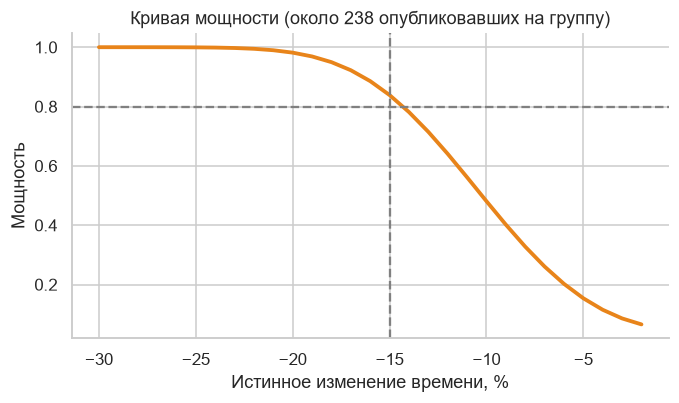

In [2]:
log_effect = np.log(1 + MDE_REL)            # ln(0.85) ≈ -0.163
d = abs(log_effect) / SIGMA_LOG
n_required = int(np.ceil(TTestIndPower().solve_power(effect_size=d, alpha=ALPHA, power=POWER,
                                                      ratio=1.0, alternative="two-sided")))
print(f"Разница на лог-шкале: {log_effect:.3f}; Cohen's d = {d:.3f}")
print(f"Необходимо пользователей на группу: {n_required}")

# запас: часть пользователей начнёт создавать опрос, но не опубликует его (для них времени нет)
PUBLISH_RATE_GUESS = 0.85
N_A = N_B = int(np.ceil(n_required * 1.10 / PUBLISH_RATE_GUESS / 10) * 10)
print(f"Планируемые размеры групп: контрольная N = {N_A}, экспериментальная M = {N_B}")

effects = np.arange(-0.30, -0.019, 0.01)
powers = [TTestIndPower().power(abs(np.log(1 + e)) / SIGMA_LOG, nobs1=int(N_A * PUBLISH_RATE_GUESS),
                                alpha=ALPHA, ratio=1.0) for e in effects]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(effects * 100, powers, color=COLORS["B"], lw=2.5)
ax.axhline(POWER, ls="--", color="gray"); ax.axvline(MDE_REL * 100, ls="--", color="gray")
ax.set(xlabel="Истинное изменение времени, %", ylabel="Мощность",
       title=f"Кривая мощности (около {int(N_A * PUBLISH_RATE_GUESS)} опубликовавших на группу)")
plt.show()

### 3.2. Генерация данных

Генерируем лог пользователей так, как его отдал бы бэкенд СВОД: по строке на пользователя, начавшего создавать первый опрос.

| Колонка | Описание |
|---|---|
| `user_id` | уникальный идентификатор пользователя |
| `group` | `A` (с нуля) / `B` (есть шаблоны) |
| `experience` | `new` — новичок / `returning` — уже создавал опросы |
| `company_size` | `small` / `medium` / `large` (немного значений пропущено) |
| `template_used` | 1, если пользователь создал опрос из шаблона (возможно только в B) |
| `published` | 1, если опрос был опубликован |
| `time_minutes` | минуты от начала создания до публикации (только для опубликовавших) |
| `n_questions` | число вопросов в опубликованном опросе |

**Заложенная в генератор «правда»:**
- новички создают опрос дольше опытных, крупные компании — дольше мелких (сложнее опросы);
- в группе B шаблоны использует не каждый: новички берут их охотнее (~78%), опытные реже (~55%);
- использование шаблона ускоряет создание: примерно на 26% у новичков и на 18% у опытных; тем, кто шаблон не взял, ничего не меняется;
- в итоге средний эффект на уровне всей группы B (ITT) оказывается около −15%;
- шаблоны почти не влияют на долю опубликованных опросов и лишь слегка увеличивают число вопросов (шаблон «приходит» с готовым набором).

Эти «истинные» параметры анализ не видит — он должен восстановить эффект из данных.

In [3]:
rng = np.random.default_rng(SEED)

def generate_experiment(n_a, n_b, rng):
    n = n_a + n_b
    group = rng.permutation(np.array(["A"] * n_a + ["B"] * n_b))
    treat = (group == "B")

    experience = rng.choice(["new", "returning"], size=n, p=[0.60, 0.40])
    company_size = rng.choice(["small", "medium", "large"], size=n, p=[0.50, 0.35, 0.15])
    is_new = (experience == "new")

    # кто воспользовался шаблоном (только в группе B)
    p_use = np.where(is_new, 0.78, 0.55)
    template_used = (treat & (rng.random(n) < p_use)).astype(int)

    # логарифм времени: базовые ~22 мин, новички и крупные компании медленнее
    log_time = (
        np.log(22)
        + 0.30 * is_new
        + 0.14 * (company_size == "large")
        - template_used * np.where(is_new, 0.30, 0.20)     # шаблон ускоряет (-26% / -18%)
        + rng.normal(0, SIGMA_LOG, size=n)
    )
    time_minutes = np.exp(log_time)

    # дошёл ли до публикации (шаблоны чуть помогают)
    published = rng.binomial(1, 0.83 + 0.03 * template_used)

    # число вопросов в опросе: шаблон приходит с готовым набором
    n_questions = rng.poisson(8, size=n) + 3 + template_used

    df = pd.DataFrame({
        "user_id": np.arange(1, n + 1), "group": group, "experience": experience,
        "company_size": company_size, "template_used": template_used,
        "published": published, "time_minutes": time_minutes, "n_questions": n_questions,
    })

    # время и число вопросов известны только для опубликовавших
    df.loc[df.published == 0, ["time_minutes", "n_questions"]] = np.nan

    # --- "грязь", как в реальных логах ---
    df.loc[rng.choice(n, size=int(0.015 * n), replace=False), "company_size"] = np.nan   # не заполнен профиль
    pub_idx = df.index[df.published == 1].to_numpy()
    out_idx = rng.choice(pub_idx, size=int(0.008 * len(pub_idx)), replace=False)
    df.loc[out_idx, "time_minutes"] *= rng.uniform(8, 20, size=len(out_idx))              # ушёл на обед, не закрыв вкладку
    return df

df = generate_experiment(N_A, N_B, rng)
print(df.shape)
df.head(8)

(560, 8)


,user_id,group,experience,company_size,template_used,published,time_minutes,n_questions
0,1,A,returning,small,0,1,582.3769,11.0000
1,2,B,returning,large,0,1,33.8373,7.0000
2,3,A,returning,large,0,0,NaN,NaN
3,4,A,new,small,0,1,29.3507,8.0000
4,5,A,new,small,0,1,90.4096,15.0000
5,6,A,returning,large,0,0,NaN,NaN
6,7,B,returning,small,1,0,NaN,NaN
7,8,B,new,medium,1,1,9.6204,10.0000


### 3.3. Проверка качества данных

In [4]:
print("Пропуски по колонкам:")
display(df.isna().sum().to_frame("n_missing").assign(share=lambda d: d.n_missing / len(df)))
print("(пропуски в time_minutes и n_questions — это не брак данных, а пользователи, не опубликовавшие опрос)\n")
print("Дубликаты user_id:", df.user_id.duplicated().sum())
print("Шаблоны использованы в группе A:", int(df.query("group=='A'").template_used.sum()), "(должно быть 0)")

Пропуски по колонкам:


,n_missing,share
user_id,0,0.0000
group,0,0.0000
experience,0,0.0000
company_size,8,0.0143
template_used,0,0.0000
published,0,0.0000
time_minutes,87,0.1554
n_questions,87,0.1554


(пропуски в time_minutes и n_questions — это не брак данных, а пользователи, не опубликовавшие опрос)

Дубликаты user_id: 0
Шаблоны использованы в группе A: 0 (должно быть 0)


Выбросов по времени: 8 из 473 (1.69%); порог сверху ≈ 129 мин


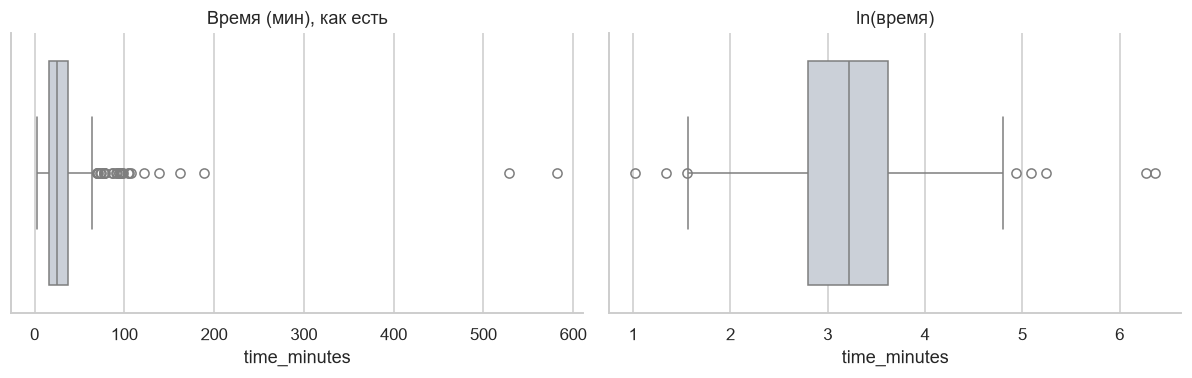

In [5]:
# Выбросы по времени: правило Тьюки (1.5·IQR) на логарифме времени
pub = df[df.published == 1].copy()
log_t = np.log(pub["time_minutes"])
q1, q3 = log_t.quantile([0.25, 0.75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
pub["is_outlier"] = ((log_t < lo) | (log_t > hi)).values
print(f"Выбросов по времени: {pub.is_outlier.sum()} из {len(pub)} ({pub.is_outlier.mean():.2%}); порог сверху ≈ {np.exp(hi):,.0f} мин")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(x=pub["time_minutes"], ax=axes[0], color="#C9CFDA"); axes[0].set_title("Время (мин), как есть")
sns.boxplot(x=log_t, ax=axes[1], color="#C9CFDA"); axes[1].set_title("ln(время)")
plt.tight_layout(); plt.show()

**Что делаем с найденным:**
- **Пропуски `company_size`** (~1.5%) — не удаляем, помечаем как `unknown`; для главной метрики поле не нужно.
- **Выбросы по времени** — это «забытые вкладки» (пользователь отошёл посреди создания), а не реальное время работы. Для **основного анализа исключаем** такие наблюдения, а в разделе 4.2 отдельно проверяем **чувствительность**: меняется ли вывод, если выбросы оставить.
- **Не опубликовавшие** опрос исключены из анализа времени (у них нет момента публикации), но участвуют в метрике-ограничении «доля опубликованных».

In [6]:
df["company_size"] = df["company_size"].fillna("unknown")
pub["company_size"] = pub["company_size"].fillna("unknown")
clean = pub[~pub.is_outlier].copy()          # основной анализ
clean["ln_time"] = np.log(clean["time_minutes"])

print("Описательная статистика времени создания (мин), по группам (без выбросов):")
desc = clean.groupby("group")["time_minutes"].agg(n="size", mean="mean", median="median", std="std",
                                                   p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75))
display(desc)

print("Доля использовавших шаблон в группе B:", f"{df.query('group==\"B\"').template_used.mean():.1%}")
display(df.groupby("group").agg(n=("user_id", "size"), published_rate=("published", "mean"),
                                new_share=("experience", lambda s: (s == "new").mean())))

Описательная статистика времени создания (мин), по группам (без выбросов):


,n,mean,median,std,p25,p75
group,,,,,,
A,226,31.7523,25.8539,19.9627,18.1909,38.7517
B,239,27.8504,23.3023,18.0702,15.1154,34.5239


Доля использовавших шаблон в группе B: 67.9%


,n,published_rate,new_share
group,,,
A,280,0.8321,0.6321
B,280,0.8571,0.6143


## Раздел 4. Статистический анализ

### 4.1. Проверка предпосылок

**Независимость наблюдений и корректность рандомизации.** Одна строка — один пользователь и его первый опрос в эксперименте; группа назначена случайно по хэшу ID и не меняется. Проверяем:
1. **SRM (Sample Ratio Mismatch)** — фактическое деление групп совпадает с плановым 50/50;
2. **Баланс ковариат** — доли новичков и размеры компаний в группах одинаковы (иначе разницу во времени можно списать на состав групп).

In [7]:
# (в синтетике группы делятся ровно пополам, поэтому SRM здесь тривиален; на реальных логах проверка важна)
n_obs = df["group"].value_counts().reindex(["A", "B"])
srm = stats.chisquare(n_obs.values, f_exp=[len(df) / 2] * 2)
print(f"SRM: A={n_obs['A']}, B={n_obs['B']}, chi2 p-value = {srm.pvalue:.3f}  ->",
      "ОК, перекоса нет" if srm.pvalue > 0.001 else "ПЕРЕКОС: тест нельзя интерпретировать!")
print(f"Баланс опыта (new/returning): chi2 p-value = {stats.chi2_contingency(pd.crosstab(df.group, df.experience))[1]:.3f}")
print(f"Баланс размера компании:      chi2 p-value = {stats.chi2_contingency(pd.crosstab(df.group, df.company_size))[1]:.3f}")
display(pd.crosstab(df["group"], df["experience"], normalize="index"))

SRM: A=280, B=280, chi2 p-value = 1.000  -> ОК, перекоса нет
Баланс опыта (new/returning): chi2 p-value = 0.727
Баланс размера компании:      chi2 p-value = 0.625


experience,new,returning
group,,
A,0.6321,0.3679
B,0.6143,0.3857


**Нормальность и однородность дисперсий.** Для сравнения средних нужны (приблизительно) нормальные данные и сопоставимый разброс в группах. Проверяем на **сырых минутах** и на **логарифме времени**. Шапиро–Уилк считаем на подвыборке 500 наблюдений, т. к. на больших выборках он «ловит» ничтожные отклонения.

,Shapiro p (A),Shapiro p (B),skew A,skew B,Levene p
переменная,,,,,
time (мин),0.0000,0.0000,1.6212,1.8980,0.3433
ln(time),0.4170,0.7016,0.0979,0.0521,0.4347


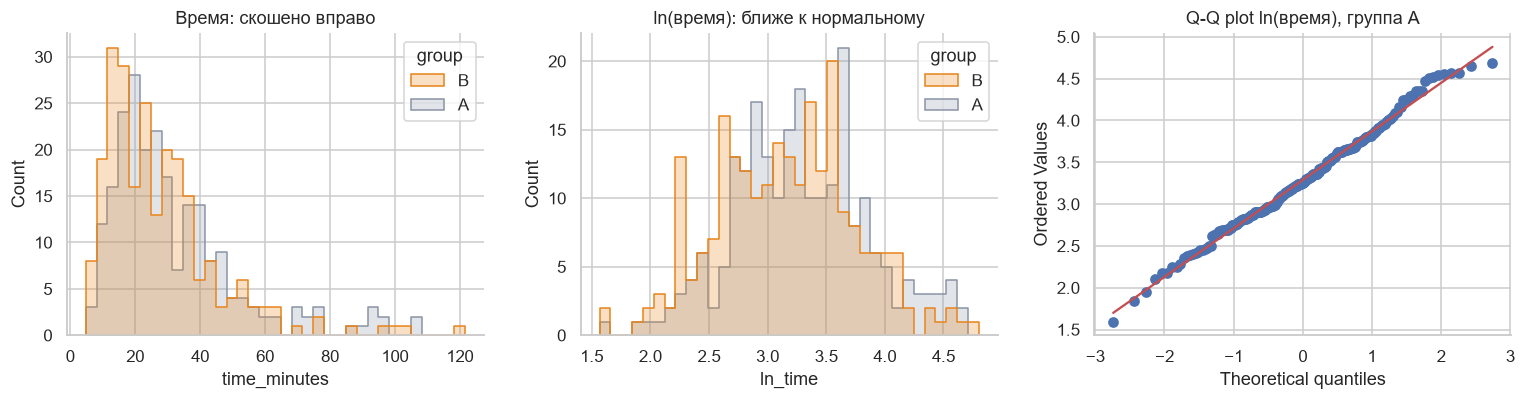

In [8]:
ta = clean.loc[clean.group == "A", "time_minutes"].values
tb = clean.loc[clean.group == "B", "time_minutes"].values
la, lb = np.log(ta), np.log(tb)

sub = lambda x: np.random.default_rng(SEED).choice(x, size=min(500, len(x)), replace=False)
rows = []
for name, a, b in [("time (мин)", ta, tb), ("ln(time)", la, lb)]:
    rows.append({"переменная": name,
                 "Shapiro p (A)": stats.shapiro(sub(a)).pvalue, "Shapiro p (B)": stats.shapiro(sub(b)).pvalue,
                 "skew A": stats.skew(a), "skew B": stats.skew(b),
                 "Levene p": stats.levene(a, b, center="median").pvalue})
display(pd.DataFrame(rows).set_index("переменная"))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(clean, x="time_minutes", hue="group", palette=COLORS, bins=35, element="step", ax=axes[0])
axes[0].set_title("Время: скошено вправо")
sns.histplot(clean, x="ln_time", hue="group", palette=COLORS, bins=35, element="step", ax=axes[1])
axes[1].set_title("ln(время): ближе к нормальному")
stats.probplot(la, dist="norm", plot=axes[2]); axes[2].set_title("Q-Q plot ln(время), группа A")
plt.tight_layout(); plt.show()

**Вывод по предпосылкам.**
- Независимость и рандомизация — выполнены (SRM и баланс ковариат в норме).
- **Сырое время** сильно скошено вправо → t-тест на минутах работал бы хуже (хотя при n в сотни центральная предельная теорема смягчает проблему).
- **ln(время)** близко к нормальному (Q-Q график почти по прямой), дисперсии групп сопоставимы (Левен) → применяем **t-тест Уэлча на ln(время)**. Версия Уэлча не требует равенства дисперсий, поэтому безопаснее классического t-теста.
- Эффект на лог-шкале читается как **отношение геометрических средних** («типичное время в B составляет X% от времени в A»), что естественно для эффекта вида «−15%».

### 4.2. Выбор и применение статистического теста

**Основной анализ.** Сравниваем средние двух независимых групп по непрерывной метрике → **t-тест Уэлча на ln(время)**. Результат переводим обратно: $e^{\Delta}-1$ — относительное изменение типичного (геометрического среднего) времени. Дополнительно, для устойчивости и чтобы напрямую ответить на «среднее время»:
- **бутстрэп-интервал** для относительного изменения *арифметического* среднего (не требует нормальности);
- **тест Манна–Уитни** (ранговый, без предположений о распределении);
- **анализ чувствительности** — тот же тест с выбросами;
- **линейная регрессия** ln(время) на группу с поправкой на опыт и размер компании (повышает точность оценки).

In [9]:
n_a, n_b = len(la), len(lb)
mean_a, mean_b = ta.mean(), tb.mean()

# 1. Welch t-test на ln(time)
tt = stats.ttest_ind(lb, la, equal_var=False)
ci = tt.confidence_interval(0.95)
log_diff = lb.mean() - la.mean()
geo_change = np.exp(log_diff) - 1
geo_lo, geo_hi = np.exp(ci.low) - 1, np.exp(ci.high) - 1

# 2. Бутстрэп: относительное изменение арифметического среднего
brng = np.random.default_rng(SEED)
boot = np.array([brng.choice(tb, n_b).mean() / brng.choice(ta, n_a).mean() - 1 for _ in range(5000)])
b_lo, b_hi = np.percentile(boot, [2.5, 97.5])
mean_change = mean_b / mean_a - 1

# 3. Манн-Уитни
mw = stats.mannwhitneyu(tb, ta, alternative="two-sided")

# 4. Welch на сырых минутах (для сравнения)
tt_raw = stats.ttest_ind(tb, ta, equal_var=False)

# 5. Размер эффекта (d на лог-шкале)
pooled = np.sqrt((la.var(ddof=1) + lb.var(ddof=1)) / 2)
cohen_d = log_diff / pooled

res = pd.DataFrame({"A (с нуля)": [n_a, mean_a, np.median(ta), np.exp(la.mean())],
                    "B (шаблоны)": [n_b, mean_b, np.median(tb), np.exp(lb.mean())]},
                   index=["опубликовали, n", "среднее, мин", "медиана, мин", "геом. среднее, мин"])
display(res)

print(f"Изменение типичного времени (геом. среднее): {geo_change:+.1%}   95% ДИ [{geo_lo:+.1%}; {geo_hi:+.1%}]")
print(f"Изменение арифметического среднего:         {mean_change:+.1%}   95% бутстрэп-ДИ [{b_lo:+.1%}; {b_hi:+.1%}]")
print(f"Welch t-test на ln(time): t = {tt.statistic:.3f}, df ≈ {tt.df:.0f}, p-value = {tt.pvalue:.5f}")
print(f"Welch t-test на минутах:  t = {tt_raw.statistic:.3f}, p-value = {tt_raw.pvalue:.5f}")
print(f"Mann-Whitney U:           p-value = {mw.pvalue:.5f}")
print(f"Cohen's d (лог-шкала) = {cohen_d:.3f}")

,A (с нуля),B (шаблоны)
"опубликовали, n",226.0000,239.0000
"среднее, мин",31.7523,27.8504
"медиана, мин",25.8539,23.3023
"геом. среднее, мин",26.8387,23.3053


Изменение типичного времени (геом. среднее): -13.2%   95% ДИ [-22.0%; -3.4%]
Изменение арифметического среднего:         -12.3%   95% бутстрэп-ДИ [-21.7%; -1.4%]
Welch t-test на ln(time): t = -2.592, df ≈ 463, p-value = 0.00984
Welch t-test на минутах:  t = -2.206, p-value = 0.02791
Mann-Whitney U:           p-value = 0.01345
Cohen's d (лог-шкала) = -0.240


In [10]:
# Анализ чувствительности: что если выбросы оставить?
with_out = pub.assign(ln_time=np.log(pub.time_minutes))
wa = with_out.loc[with_out.group == "A", "ln_time"]; wb = with_out.loc[with_out.group == "B", "ln_time"]
tt_o = stats.ttest_ind(wb, wa, equal_var=False)
print(f"С выбросами: изменение геом. среднего {np.exp(wb.mean() - wa.mean()) - 1:+.1%}, p-value = {tt_o.pvalue:.5f}")
print(f"Без выбросов: изменение геом. среднего {geo_change:+.1%}, p-value = {tt.pvalue:.5f}")

# Регрессия с поправкой на ковариаты
d = clean.assign(treat=(clean.group == "B").astype(int))
ols = smf.ols("ln_time ~ treat + C(experience) + C(company_size)", data=d).fit(cov_type="HC3")
adj = np.exp(ols.params["treat"]) - 1
adj_ci = np.exp(ols.conf_int().loc["treat"]) - 1
print(f"\nС поправкой на опыт и размер компании: {adj:+.1%}  95% ДИ [{adj_ci[0]:+.1%}; {adj_ci[1]:+.1%}], p = {ols.pvalues['treat']:.5f}")

С выбросами: изменение геом. среднего -16.4%, p-value = 0.00300
Без выбросов: изменение геом. среднего -13.2%, p-value = 0.00984

С поправкой на опыт и размер компании: -13.4%  95% ДИ [-22.1%; -3.6%], p = 0.00829


**Intention-to-treat и эффект для «взявших шаблон».** Все числа выше — **ITT**: эффект запуска фичи на всю группу B, включая тех, кто шаблон проигнорировал. Это реальный ответ на вопрос «что мы получим после запуска». Приближённо можно оценить и эффект *для тех, кто воспользовался шаблоном*: разделить ITT-эффект (на лог-шкале) на долю использования (оценка CACE, метод инструментальной переменной).

In [11]:
adoption = df.query("group == 'B'")["template_used"].mean()
cace_log = log_diff / adoption
print(f"Доля использовавших шаблон в B: {adoption:.1%}")
print(f"ITT (вся группа B):        {geo_change:+.1%}")
print(f"CACE (взявшие шаблон):     {np.exp(cace_log) - 1:+.1%}   (оценка эффекта на тех, кто фичей воспользовался)")

Доля использовавших шаблон в B: 67.9%
ITT (вся группа B):        -13.2%
CACE (взявшие шаблон):     -18.8%   (оценка эффекта на тех, кто фичей воспользовался)


**Метрики-ограничения (guardrails).**
1. **Доля опубликованных опросов** — не должна упасть.
2. **Число вопросов** в опубликованном опросе — не должно раздуваться.

In [12]:
g = df.groupby("group")["published"].agg(["sum", "count"])
xa, na = g.loc["A"]; xb, nb = g.loc["B"]
z_pub, p_pub = proportions_ztest([xb, xa], [nb, na])
lo_, hi_ = confint_proportions_2indep(xb, nb, xa, na, method="newcomb")
print(f"Доля опубликованных: A = {xa / na:.1%}, B = {xb / nb:.1%}, Δ = {(xb / nb - xa / na) * 100:+.1f} п.п. "
      f"[{lo_ * 100:+.1f}; {hi_ * 100:+.1f}], p-value = {p_pub:.4f}")

qa = clean.loc[clean.group == "A", "n_questions"]; qb = clean.loc[clean.group == "B", "n_questions"]
mwq = stats.mannwhitneyu(qb, qa)
print(f"Число вопросов: A = {qa.mean():.1f}, B = {qb.mean():.1f}, Mann-Whitney p-value = {mwq.pvalue:.4f}")

Доля опубликованных: A = 83.2%, B = 85.7%, Δ = +2.5 п.п. [-3.5; +8.5], p-value = 0.4142
Число вопросов: A = 10.9, B = 11.7, Mann-Whitney p-value = 0.0026


**Сегментный анализ** (новички / опытные). Сегментов несколько, поэтому p-value корректируем на множественные сравнения (поправка Холма). Это *исследовательский* анализ: решение принимаем по основной метрике.

In [13]:
seg_rows = []
for exp_ in ["new", "returning"]:
    s = clean[clean.experience == exp_]
    a_, b_ = s.loc[s.group == "A", "ln_time"], s.loc[s.group == "B", "ln_time"]
    t_ = stats.ttest_ind(b_, a_, equal_var=False); c_ = t_.confidence_interval(0.95)
    seg_rows.append({"сегмент": exp_, "n A": len(a_), "n B": len(b_),
                     "Δ время, %": (np.exp(b_.mean() - a_.mean()) - 1) * 100,
                     "ДИ низ": (np.exp(c_.low) - 1) * 100, "ДИ верх": (np.exp(c_.high) - 1) * 100, "p-value": t_.pvalue})
seg = pd.DataFrame(seg_rows).set_index("сегмент")
seg["p (Холм)"] = multipletests(seg["p-value"], method="holm")[1]
display(seg)

,n A,n B,"Δ время, %",ДИ низ,ДИ верх,p-value,p (Холм)
сегмент,,,,,,,
new,140,148,-13.8757,-25.0053,-1.0944,0.0345,0.0689
returning,86,91,-11.9884,-25.4308,3.8773,0.1302,0.1302


### 4.3. Визуализация результатов

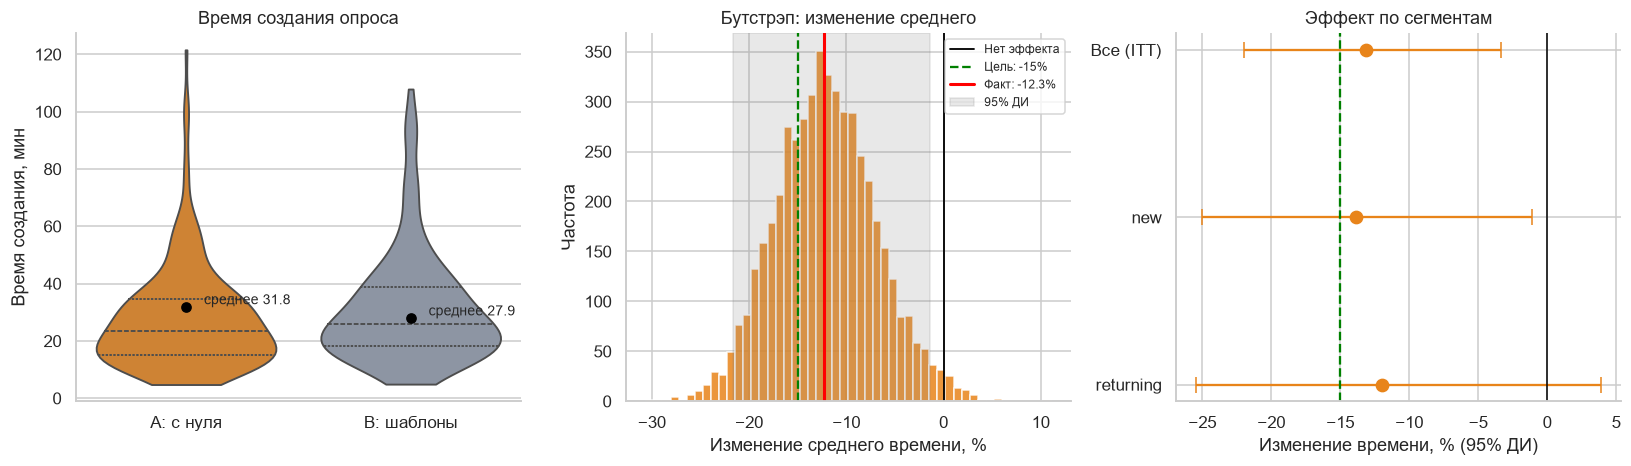

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

# (1) распределение времени
ax = axes[0]
sns.violinplot(data=clean, x="group", y="time_minutes", palette=COLORS, inner="quartile", cut=0, ax=ax)
for i, grp in enumerate(["A", "B"]):
    m = clean.loc[clean.group == grp, "time_minutes"].mean()
    ax.scatter(i, m, color="black", zorder=5); ax.text(i + 0.08, m, f"среднее {m:.1f}", fontsize=9, va="bottom")
ax.set_xticks([0, 1], ["A: с нуля", "B: шаблоны"])
ax.set(xlabel="", ylabel="Время создания, мин", title="Время создания опроса")

# (2) бутстрэп-распределение изменения среднего
ax = axes[1]
ax.hist(boot * 100, bins=50, color=COLORS["B"], alpha=0.85)
ax.axvline(0, color="black", lw=1.2, label="Нет эффекта")
ax.axvline(MDE_REL * 100, color="green", ls="--", lw=1.5, label=f"Цель: {MDE_REL * 100:.0f}%")
ax.axvline(mean_change * 100, color="red", lw=2, label=f"Факт: {mean_change * 100:+.1f}%")
ax.axvspan(b_lo * 100, b_hi * 100, color="gray", alpha=0.18, label="95% ДИ")
ax.set(xlabel="Изменение среднего времени, %", ylabel="Частота", title="Бутстрэп: изменение среднего")
ax.legend(fontsize=8)

# (3) эффект по сегментам
ax = axes[2]
rows = [("Все (ITT)", geo_change * 100, geo_lo * 100, geo_hi * 100)] + [(i, r["Δ время, %"], r["ДИ низ"], r["ДИ верх"]) for i, r in seg.iterrows()]
for k, (name, m, lo_, hi_) in enumerate(rows[::-1]):
    ax.errorbar(m, k, xerr=[[m - lo_], [hi_ - m]], fmt="o", color=COLORS["B"], capsize=5, ms=8)
ax.axvline(0, color="black", lw=1); ax.axvline(MDE_REL * 100, color="green", ls="--")
ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]])
ax.set(xlabel="Изменение времени, % (95% ДИ)", title="Эффект по сегментам")
plt.tight_layout(); plt.show()

## Раздел 5. Интерпретация и выводы

### 5.1. Статистический вывод

In [15]:
from IPython.display import Markdown

significant = tt.pvalue < ALPHA
decision = "**отвергаем H₀**" if significant else "**не отвергаем H₀**"
verdict = ("время создания опроса в группах статистически значимо различается" if significant
           else "данных недостаточно, чтобы утверждать, что шаблоны влияют на время создания")
display(Markdown(f'''
- **P-value (t-тест Уэлча на ln(время)) = {tt.pvalue:.5f}** (Манн–Уитни: {mw.pvalue:.5f}; регрессия с поправкой: {ols.pvalues["treat"]:.5f}) при α = {ALPHA}
- **Статистическое решение:** {decision}: {verdict}.
- Среднее время: **{mean_a:.1f} → {mean_b:.1f} мин**, изменение **{mean_change:+.1%}** (95% бутстрэп-ДИ: [{b_lo:+.1%}; {b_hi:+.1%}]).
- Типичное время (геометрическое среднее): изменение **{geo_change:+.1%}** (95% ДИ: [{geo_lo:+.1%}; {geo_hi:+.1%}]).
- Эффект для взявших шаблон (CACE): **{np.exp(cace_log) - 1:+.1%}** при доле использования {adoption:.0%}.
'''))


- **P-value (t-тест Уэлча на ln(время)) = 0.00984** (Манн–Уитни: 0.01345; регрессия с поправкой: 0.00829) при α = 0.05
- **Статистическое решение:** **отвергаем H₀**: время создания опроса в группах статистически значимо различается.
- Среднее время: **31.8 → 27.9 мин**, изменение **-12.3%** (95% бутстрэп-ДИ: [-21.7%; -1.4%]).
- Типичное время (геометрическое среднее): изменение **-13.2%** (95% ДИ: [-22.0%; -3.4%]).
- Эффект для взявших шаблон (CACE): **-18.8%** при доле использования 68%.


### 5.2. Бизнес-вывод

In [16]:
MONTHLY_SURVEYS = 1_000       # допущение: сколько опросов в месяц создают клиенты СВОД
saved_min = (mean_a - mean_b)
saved_hours = saved_min * MONTHLY_SURVEYS / 60
saved_lo = (mean_a * -b_hi) * MONTHLY_SURVEYS / 60     # консервативная оценка по границе ДИ
saved_hi = (mean_a * -b_lo) * MONTHLY_SURVEYS / 60

practical = b_hi <= MDE_REL          # весь ДИ не хуже цели
practical_point = mean_change <= MDE_REL
point_txt = "достигает цели" if practical_point else "не дотягивает до цели (сокращение меньше 15%)"
low_txt = ("весь доверительный интервал не хуже цели (эффект практически значим с высокой уверенностью)" if practical
           else f"худшая граница ДИ ({b_hi:+.1%}) слабее цели {MDE_REL:.0%}: нельзя утверждать, что цель гарантированно достигнута")
pub_ok = "доля опубликованных не упала" if (p_pub > ALPHA or xb / nb >= xa / na) else "доля опубликованных упала — требует внимания"
q_ok = "число вопросов не изменилось заметно" if mwq.pvalue > ALPHA else f"число вопросов отличается (A: {qa.mean():.1f}, B: {qb.mean():.1f}) — шаблон «приносит» свои вопросы"
n_d, r_d = seg.loc["new", "Δ время, %"], seg.loc["returning", "Δ время, %"]
n_p, r_p = seg.loc["new", "p (Холм)"], seg.loc["returning", "p (Холм)"]

display(Markdown(f'''
**Практическая значимость.** Цель — {MDE_REL:.0%} к среднему времени. Точечная оценка {mean_change:+.1%} — {point_txt}; {low_txt}.

**Что это значит для продукта (при допущении {MONTHLY_SURVEYS:,} создаваемых опросов в месяц):**
- экономия ≈ **{saved_min:.1f} мин на опрос**, то есть **≈ {saved_hours:,.0f} часов в месяц** у клиентов (интервал {saved_lo:,.0f} … {saved_hi:,.0f});
- быстрее создание первого опроса — выше вероятность активации новичка (гипотеза о связи с удержанием в этом тесте не проверялась);
- guardrails: {pub_ok} ({xa / na:.1%} → {xb / nb:.1%}, p = {p_pub:.3f}); {q_ok} (p = {mwq.pvalue:.3f}).

**Сегменты:** у новичков время изменилось на {n_d:+.1f}%, у опытных на {r_d:+.1f}% (p с поправкой Холма: {n_p:.4f} и {r_p:.4f}). Сегментный анализ исследовательский — выборка не рассчитывалась на мощность в подгруппах.

**Интерпретация ITT и CACE.** ITT ({geo_change:+.1%}) — реальный эффект запуска на всех. Эффект на тех, кто взял шаблон (CACE {np.exp(cace_log) - 1:+.1%}), сильнее: часть пользователей шаблоны игнорирует. Значит, у фичи есть резерв: чем выше доля использования (подсказки, показ шаблонов на пустом холсте), тем ближе общий эффект к CACE.
'''))


**Практическая значимость.** Цель — -15% к среднему времени. Точечная оценка -12.3% — не дотягивает до цели (сокращение меньше 15%); худшая граница ДИ (-1.4%) слабее цели -15%: нельзя утверждать, что цель гарантированно достигнута.

**Что это значит для продукта (при допущении 1,000 создаваемых опросов в месяц):**
- экономия ≈ **3.9 мин на опрос**, то есть **≈ 65 часов в месяц** у клиентов (интервал 7 … 115);
- быстрее создание первого опроса — выше вероятность активации новичка (гипотеза о связи с удержанием в этом тесте не проверялась);
- guardrails: доля опубликованных не упала (83.2% → 85.7%, p = 0.414); число вопросов отличается (A: 10.9, B: 11.7) — шаблон «приносит» свои вопросы (p = 0.003).

**Сегменты:** у новичков время изменилось на -13.9%, у опытных на -12.0% (p с поправкой Холма: 0.0689 и 0.1302). Сегментный анализ исследовательский — выборка не рассчитывалась на мощность в подгруппах.

**Интерпретация ITT и CACE.** ITT (-13.2%) — реальный эффект запуска на всех. Эффект на тех, кто взял шаблон (CACE -18.8%), сильнее: часть пользователей шаблоны игнорирует. Значит, у фичи есть резерв: чем выше доля использования (подсказки, показ шаблонов на пустом холсте), тем ближе общий эффект к CACE.


### 5.3. Рекомендации

In [17]:
if significant and mean_change < 0 and practical:
    rec = "✅ **Внедрять шаблоны для всех пользователей.** Время создания значимо сократилось, и цель −15% достигается с высокой уверенностью."
elif significant and mean_change < 0:
    rec = f"🟡 **Внедрять, но осторожно** (поэтапная раскатка 10% → 50% → 100%): время значимо сократилось, однако нельзя гарантировать цель {MDE_REL:.0%} — нижняя граница эффекта слабее."
elif significant and mean_change > 0:
    rec = "❌ **Не внедрять:** шаблоны увеличили время создания опроса."
else:
    rec = "⏸ **Решение не принимать на основе этого теста:** эффект не доказан; нужен больший эксперимент или пересмотр гипотезы."
display(Markdown(rec))

🟡 **Внедрять, но осторожно** (поэтапная раскатка 10% → 50% → 100%): время значимо сократилось, однако нельзя гарантировать цель -15% — нижняя граница эффекта слабее.

**Дальнейшие шаги**
1. Поэтапная раскатка (feature flag): 10% → 50% → 100% с мониторингом времени создания, доли публикаций и числа вопросов.
2. **Поднять долю использования шаблонов**: показывать шаблоны на пустом холсте, а не отдельной вкладкой, рекомендовать шаблон по цели опроса (первый вопрос «Для чего опрос?»).
3. Через аналитику выбора понять, какие из 10 шаблонов популярны, и заменить невостребованные; добавить пользовательские шаблоны («сохранить опрос как шаблон»).
4. Проверить **качество получаемых опросов**: не растёт ли доля опросов с неотредактированными «чужими» вопросами (в СВОД есть проверка качества ответов, её можно использовать как косвенный сигнал).
5. Проверить гипотезу про **активацию и удержание**: сравнить долю новичков, создавших второй опрос за 14 дней, в группах A и B.
6. Следующий эксперимент: ИИ-генерация опроса по описанию цели — ещё больше сокращает время.

**Ограничения исследования**
- **Данные синтетические**: выводы демонстрируют *методику*; реальный эффект шаблонов необходимо подтвердить на живом трафике СВОД.
- **Условие на публикацию:** время известно только у тех, кто опубликовал опрос, а шаблоны могут менять, *кто* доходит до публикации. Сравнение «среди опубликовавших» поэтому может быть слегка смещено; мы смягчаем это проверкой доли опубликованных (guardrail).
- Время измеряется по логам «начало создания → публикация» и включает паузы пользователя; выбросы («забытые вкладки») исключены, чувствительность проверена.
- Бизнес-оценка (1 000 опросов/мес) — допущение, а не измерение.
- Эффект новизны: на коротком горизонте пользователи могут активнее пробовать шаблоны, чем в долгосрочной перспективе.
- Измерялся только **первый** опрос в эксперименте; у опытных пользователей эффект на последующих опросах может отличаться.
- Сегментный анализ исследовательский: выборка не рассчитывалась на мощность в подгруппах.
- Тест не оценивает ценность опросов, созданных из шаблона (отклик респондентов, качество данных).